# Health — descriptives (ADM2 panel)

**Question.** Does upstream land-cover change affect health in downstream municipalities?
**Unit.** Municipality (ADM2, 6-digit IBGE `mun_id`) × year (`data/assembly/adm2_panel.parquet`).

As for pollution, this notebook gathers the descriptive evidence needed to choose the
model in [`02_analysis.ipynb`](02_analysis.ipynb). Each section ends with an **→ Informs**
note; §9 collects them into a decision table.

> **Data status.** SIH hospitalizations, SINASC births, SIM deaths and each
> municipality's dominant Otto basin are assembled into `adm2_panel`; §0 checks them
> against the processed health tables.

| § | Topic | Informs |
|---|---|---|
| 0 | Data readiness & join | blockers, key mismatches |
| 1 | Coverage & estimation window | window, municipality sample |
| 2 | Outcomes: definition & distributions | outcome set, rates vs counts, weighting, series breaks |
| 3 | Outcome variance decomposition | FE structure |
| 4 | Land-cover exposure variation | identified classes, FE cost |
| 5 | Local vs upstream exposure, distance | exposure definition, kernel/bandwidth |
| 6 | Controls | control set |
| 7 | Inference structure | cluster level |
| 8 | Raw associations, placebo under the candidate specification | sign/shape priors, exposure set, controls |
| 9 | Decision table | — |

In [1]:
import sys
from pathlib import Path

PROJECT_ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "pyproject.toml").exists())
sys.path.insert(0, str(PROJECT_ROOT))

import json

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

from src.analysis import descriptives as desc
from src.analysis import panels

pd.set_option("display.max_rows", 200)
pd.set_option("display.max_columns", 60)
pd.set_option("display.width", 220)
pd.set_option("display.float_format", lambda v: f"{v:,.4g}")
plt.rcParams.update({"figure.dpi": 100, "axes.spines.top": False, "axes.spines.right": False})

In [2]:
# Morbidity channels with a plausible waterborne pathway vs. placebo channels
# that should not respond to upstream water quality.
WATER_CHANNELS = [
    "water_sanitation_gastrointestinal", "leptospirosis_water_exposure",
    "renal_urinary_toxic_water", "toxic_poisoning", "skin_contact",
    "vector_borne_ecological", "perinatal_newborn", "congenital_anomalies",
]
PLACEBO_CHANNELS = ["injuries_accidents_occupational", "violence_self_harm", "mental_health_substance_use"]

# ICD-10 chapters: consistent across the SIH legacy/current switch (see §0), unlike the channels.
ICD_OUTCOMES = {
    "01": "infectious_parasitic",
    "11": "digestive",
    "14": "genitourinary",
    "16": "perinatal",
    "17": "congenital",
    "19": "injury_poisoning",  # placebo-ish: external causes
}

## 0. Data readiness and join

In [3]:
adm2 = (panels.load_adm2_panel(years=None)
        .rename(columns={f"hosp_icd_{code}": f"hosp_icd_{name}" for code, name in ICD_OUTCOMES.items()}))
health_columns = [c for c in adm2.columns if c.startswith(("hosp_", "births", "deaths"))]
print(f"Health columns in adm2_panel: {len(health_columns)}")
print(f"adm2_panel: {len(adm2):,} rows · {adm2.mun_id.nunique():,} municipalities · {adm2.year.min()}–{adm2.year.max()}")

Health columns in adm2_panel: 59
adm2_panel: 222,560 rows · 5,564 municipalities · 1985–2024


Key mismatches: health codes absent from the panel (GADM's ADM2 layer predates some municipalities; `000000` is "unknown / abroad").

In [4]:
# Assembly left-joins health onto the panel, so codes absent from it are checked
# against the processed SIH table directly.
sih_totals = pd.read_parquet(panels.HEALTH_PROCESSED_DIR / "health_hospitalizations.parquet",
                             columns=["municipality_code", "municipality_name", "metric_name", "metric_value"],
                             filters=[("metric_name", "==", "hospitalizations_count")])
names = sih_totals.drop_duplicates("municipality_code").set_index("municipality_code")["municipality_name"]
hosp_by_code = sih_totals.groupby("municipality_code")["metric_value"].sum()
panel_ids = set(adm2["mun_id"])
health_ids = set(hosp_by_code.index)
unmatched = sorted(health_ids - panel_ids)
print(f"Health municipalities: {len(health_ids):,}; not in adm2_panel: {len(unmatched)}; "
      f"panel municipalities without health: {len(panel_ids - health_ids)}")
unmatched_hosp = hosp_by_code.reindex(unmatched)
display(pd.DataFrame({"name": names.reindex(unmatched), "hospitalizations_all_years": unmatched_hosp})
        .sort_values("hospitalizations_all_years", ascending=False).head(15))
print(f"Share of all hospitalizations in unmatched codes: "
      f"{unmatched_hosp.sum() / hosp_by_code.sum():.2%}")

Health municipalities: 5,571; not in adm2_panel: 7; panel municipalities without health: 0


,name,hospitalizations_all_years
municipality_code,,
000000,Ignorado ou exterior,1.869e+06
330023,ARMACAO DOS BUZIOS,4.034e+04
291992,MADRE DE DEUS,2.474e+04
430105,ARROIO DO SAL,1.381e+04
353310,NOVA GUATAPORANGA,"6,615"
350060,AGUAS DE SAO PEDRO,"4,664"
260545,FERNANDO DE NORONHA,"3,145"


Share of all hospitalizations in unmatched codes: 0.56%


In [5]:
df = adm2.copy()
df["source_system"] = panels.sih_source_system(df["year"])
df["population"] = df["population"].astype(float)
df["state"] = df["mun_id"].str[:2]
df["state_year"] = df["state"] + "_" + df["year"].astype(str)
df["biome_year"] = df["biome"] + "_" + df["year"].astype(str)

availability = df.groupby("year").agg(
    population=("population", lambda x: x.notna().mean()),
    hospitalizations=("hosp_hospitalizations_count", lambda x: x.notna().mean()),
    births=("births", lambda x: x.notna().mean()),
    deaths=("deaths_total", lambda x: x.notna().mean()),
    source_system=("source_system", "first"),
)
display(availability.T)

year,1985,1986,1987,1988,1989,1990,1991,1992,1993,1994,1995,1996,1997,1998,1999,2000,2001,2002,2003,2004,2005,2006,2007,2008,2009,2010,2011,2012,2013,2014,2015,2016,2017,2018,2019,2020,2021,2022,2023,2024
population,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0.9887,0.9982,0.9989,0.9982,0.9989,0.9989,0.9989,0.9989,0.9991,0.9991,0.9991,0.9991,0.9991,1,1,1,1,1,1,1,1,1,1,1,1
hospitalizations,0,0,0,0,0,0,0,0,0,0,0.8817,0.8882,0.8902,0.9881,0.9885,0.9887,0.9887,0.9977,0.9982,0.998,0.998,0.9986,0.9984,0.998,0.9991,0.9991,0.9991,0.9991,0.9998,1,1,1,1,1,1,1,1,1,1,1
births,0,0,0,0,0,0,0,0,0,0.7883,0.8413,0.8647,0.9687,0.9845,0.9876,0.9887,0.9964,0.9982,0.9982,0.9982,0.9984,0.9989,0.9989,0.9989,0.9991,0.9991,0.9991,0.9991,1,1,1,1,1,1,1,1,1,1,0.9998,1
deaths,0.7243,0.7293,0.7344,0.7405,0.7822,0.7946,0.7973,0.8106,0.8778,0.8792,0.8828,0.8853,0.9716,0.9775,0.9847,0.9869,0.9973,0.998,0.998,0.9982,0.9987,0.9989,0.9989,0.9987,0.9991,0.9991,0.9987,0.9991,0.9998,1,1,1,1,1,1,1,1,1,1,1
source_system,legacy,legacy,legacy,legacy,legacy,legacy,legacy,legacy,legacy,legacy,legacy,legacy,legacy,legacy,legacy,legacy,legacy,legacy,legacy,legacy,legacy,legacy,legacy,current,current,current,current,current,current,current,current,current,current,current,current,current,current,current,current,current


**Births bin check.** The bins of each SINASC table should sum to `Total` in every year;
an earlier download lost the modal bin (37–41 weeks, 3000–3999 g) in some years.

In [6]:
for name, file_name in [("gestation", "health_gestational_duration"), ("birth weight", "health_birth_weight")]:
    table = pd.read_parquet(panels.HEALTH_PROCESSED_DIR / f"{file_name}.parquet")
    bins = [c for c in table.columns if c not in ("mun_id", "mun_name", "year", "Total")]
    ratio = table.groupby("year").apply(lambda t: t[bins].sum(axis=1).sum() / t["Total"].sum())
    print(f"{name}: years where bins sum to < 99% of Total:", ratio[ratio < 0.99].round(3).to_dict())

gestation: years where bins sum to < 99% of Total: {}
birth weight: years where bins sum to < 99% of Total: {}


**SIH series consistency.** National totals in the last legacy-adjacent year vs. a current-system
year. A ratio near 1 means the category is comparable across the 2007/2008 switch.
Morbidity channels are available for 1998–2024.

In [7]:
CHANNEL_COLUMNS = panels.hospitalization_columns("morbidity_channel")
ICD_COLUMNS = [c for c in df.columns if c.startswith("hosp_icd_")]
national_totals = df.groupby("year")[CHANNEL_COLUMNS + ICD_COLUMNS].sum()
display(pd.DataFrame({
    "2006": national_totals.loc[2006],
    "2010": national_totals.loc[2010],
    "ratio 2010/2006": national_totals.loc[2010] / national_totals.loc[2006],
}))

,2006,2010,ratio 2010/2006
hosp_cardiovascular_pollution_sensitive,9.193e+05,8.673e+05,0.9435
hosp_congenital_anomalies,5.808e+04,5.046e+04,0.8688
hosp_injuries_accidents_occupational,6.882e+05,8.124e+05,1.18
hosp_leptospirosis_water_exposure,"2,763","2,617",0.9472
hosp_mental_health_substance_use,1.706e+05,1.754e+05,1.028
hosp_perinatal_newborn,2.055e+05,1.999e+05,0.9729
hosp_pregnancy_maternal,1.028e+06,1.091e+06,1.061
hosp_renal_urinary_toxic_water,4.283e+05,4.808e+05,1.122
hosp_respiratory_air_dust,1.447e+06,1.355e+06,0.9367
hosp_skin_contact,1.521e+05,2.046e+05,1.345


**Findings (run of 2026-10-22).**
- **Assembly.** Hospitalizations, births, deaths and Otto basins come from `adm2_panel`.
- **Unmatched municipalities.** 7 SIH codes are not in the panel (0.6% of
  hospitalizations, mostly "ignored/abroad" and small coastal or island municipalities
  without river matches).
- **Morbidity channels.** All channels are complete for 1998–2024 after the re-download
  (health README, blocker 2). They are continuous across the 2007/2008 switch: 2010/2006
  ratios are 0.87–1.35, except vector-borne (2.3, the 2010 dengue epidemic) and
  violence/self-harm (a few hundred cases nationally). Injuries in legacy 2000 list fewer
  causes than other years.
- **Births bins.** Every year's SINASC bins now sum to `Total`; the missing modal bins
  came from the earlier download, not from the bin labels.
- **Deaths.** SIM covers 1979–2024 (ICD-9 to 1995, ICD-10 from 1996). Before 2000 the panel
  finds 72–98% of today's municipalities in it. Municipalities created later are missing
  in those years; their deaths are presumably recorded under the municipality they were
  split from.

**→ Informs:** which unmatched municipalities matter; no data gaps remain inside the
2000–2024 window.

## 1. Coverage and estimation window

In [8]:
# Population (denominator) starts in 2000; land cover ends in 2024.
ANALYSIS_YEARS = (2000, 2024)
df = df[df["year"].between(*ANALYSIS_YEARS)].reset_index(drop=True)
print(f"Analysis sample: {len(df):,} municipality-years · {df.mun_id.nunique():,} municipalities · "
      f"{ANALYSIS_YEARS[0]}–{ANALYSIS_YEARS[1]}")
display(df.drop_duplicates("mun_id")["biome"].value_counts().rename("municipalities").to_frame().T)
display(df.groupby("year")["population"].sum().rename("population in panel").to_frame().T)

Analysis sample: 139,100 municipality-years · 5,564 municipalities · 2000–2024


biome,Mata Atlântica,Cerrado,Caatinga,Amazônia,Pampa,Pantanal
municipalities,2695,1102,1096,502,160,9


year,2000,2001,2002,2003,2004,2005,2006,2007,2008,2009,2010,2011,2012,2013,2014,2015,2016,2017,2018,2019,2020,2021,2022,2023,2024
population in panel,1.737e+08,1.762e+08,1.828e+08,1.807e+08,1.829e+08,1.849e+08,1.87e+08,1.89e+08,1.91e+08,1.929e+08,1.948e+08,1.983e+08,1.983e+08,1.999e+08,2.017e+08,2.034e+08,2.051e+08,2.067e+08,2.084e+08,2.101e+08,2.117e+08,2.132e+08,2.108e+08,2.116e+08,2.125e+08


**Findings (run of 2026-10-22).** Population starts in 2000 and land cover ends in 2024, so the window is 2000–2024:
139,100 municipality-years across 5,564 municipalities, of which 217 are headwater
municipalities without upstream area. Within it, population, hospitalization, births and
deaths coverage is above 98.7% in 2000 and above 99.6% from 2001. Only 7 SIH codes are
not in the panel (0.6% of hospitalizations, mostly "ignored/abroad" and small coastal or
island municipalities without river matches).

**→ Informs:** estimation window and whether the unmatched / missing-population municipalities need handling.

## 2. Outcomes: definition and distributions

In [9]:
PER = 1_000
rates = pd.DataFrame(index=df.index)
rates["hosp_rate"] = df["hosp_hospitalizations_count"] / df["population"] * PER
rates["hosp_death_rate"] = df["hosp_in_hospital_deaths_count"] / df["population"] * PER
for name in ICD_OUTCOMES.values():
    rates[f"rate_icd_{name}"] = df[f"hosp_icd_{name}"] / df["population"] * PER
# Morbidity channels: 1998-2024.
for channel in WATER_CHANNELS + PLACEBO_CHANNELS:
    rates[f"rate_{channel}"] = df[f"hosp_{channel}"] / df["population"] * PER
rates["births_rate"] = df["births"] / df["population"] * PER
rates["low_birth_weight_share"] = df["births_low_weight"] / df["births_weight_known"]
rates["preterm_share"] = df["births_preterm"] / df["births_gestation_known"]
# SIM deaths: all-cause per 1,000 population; infant and under-5 per 1,000 live births.
rates["mortality_rate"] = df["deaths_total"] / df["population"] * PER
rates["infant_mortality_rate"] = df["deaths_under_1"] / df["births"].where(df["births"] > 0) * PER
rates["under5_mortality_rate"] = (df["deaths_under_1"] + df["deaths_1_to_4"]) / df["births"].where(df["births"] > 0) * PER
RATE_COLUMNS = rates.columns.tolist()
df = df.join(rates)

display(desc.distribution_table(df, RATE_COLUMNS))
display(df[[c for c in df.columns if c.startswith("hosp_icd_")]].isna().mean()
        .rename("share missing").to_frame().T)

,n,share_zero,share_negative,n_distinct,modal_value,modal_share,min,p01,median,p99,p999,max,skew,skew_log_positive
hosp_rate,1.389e+05,0,0,1.339e+05,62.5,0.0001872,0.1757,16.49,62.95,143.9,212.7,"3,077",11.4,-1.336
hosp_death_rate,1.389e+05,0.01097,0,1.043e+05,0,0.01097,0,0,1.976,6.236,8.369,169,12.65,-1.002
rate_icd_infectious_parasitic,1.39e+05,0.003346,0,1.179e+05,0,0.003346,0,0.3997,4.147,31.94,61.62,167.4,3.891,-0.05976
rate_icd_digestive,1.39e+05,0.001288,0,1.179e+05,0,0.001288,0,0.9064,5.656,17.25,28.72,340,8.161,-0.8197
rate_icd_genitourinary,1.39e+05,0.00236,0,1.148e+05,0,0.00236,0,0.5316,4.141,15.58,25.28,249.5,5.558,-0.6175
rate_icd_perinatal,1.39e+05,0.05797,0,9.066e+04,0,0.05797,0,0,0.8177,4.592,11.59,64.67,9.446,-0.3646
rate_icd_congenital,1.39e+05,0.1407,0,7.353e+04,0,0.1407,0,0,0.3163,1.615,3.362,22.04,6.352,-0.2204
rate_icd_injury_poisoning,1.39e+05,0.002224,0,1.16e+05,0,0.002224,0,0.5776,4.733,14.26,20.97,324.9,10.07,-0.9815
rate_water_sanitation_gastrointestinal,1.39e+05,0.07207,0,1.053e+05,0,0.07207,0,0,1.278,22.99,42.11,111.4,3.765,-0.1474
rate_leptospirosis_water_exposure,1.39e+05,0.89,0,1.447e+04,0,0.89,0,0,0,0.2866,0.9828,5.5,21.57,0.08656


,hosp_icd_infectious_parasitic,hosp_icd_02,hosp_icd_03,hosp_icd_04,hosp_icd_05,hosp_icd_06,hosp_icd_07,hosp_icd_08,hosp_icd_09,hosp_icd_10,hosp_icd_digestive,hosp_icd_12,hosp_icd_13,hosp_icd_genitourinary,hosp_icd_15,hosp_icd_perinatal,hosp_icd_congenital,hosp_icd_18,hosp_icd_injury_poisoning,hosp_icd_20,hosp_icd_21,hosp_icd_99
share missing,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0.2,0,0.8


Small-number noise: dispersion of each rate by population decile. Strongly falling dispersion with size argues for population weights or a count model (PPML with population exposure) over OLS on rates.

In [10]:
decile = pd.qcut(df["population"], 10, labels=[f"D{i}" for i in range(1, 11)])
dispersion = (df.groupby(decile, observed=True)[RATE_COLUMNS].std()
              / df.groupby(decile, observed=True)[RATE_COLUMNS].mean())
display(dispersion.T.round(2))

population,D1,D2,D3,D4,D5,D6,D7,D8,D9,D10
hosp_rate,0.41,0.59,0.42,0.42,0.42,0.42,0.4,0.36,0.33,0.28
hosp_death_rate,0.69,0.91,0.63,0.62,0.63,0.63,0.62,0.58,0.57,0.42
rate_icd_infectious_parasitic,1.1,1.18,1.18,1.1,1.07,1.12,1.04,0.87,0.86,0.82
rate_icd_digestive,0.57,0.75,0.56,0.62,0.57,0.58,0.54,0.54,0.46,0.37
rate_icd_genitourinary,0.69,0.89,0.7,0.69,0.69,0.67,0.63,0.56,0.52,0.44
rate_icd_perinatal,1.33,1.14,1.21,1,1.17,1.06,1.14,1.01,0.86,0.68
rate_icd_congenital,1.36,1.16,1.01,0.97,1.04,0.85,0.93,0.96,0.63,0.5
rate_icd_injury_poisoning,0.62,0.78,0.57,0.56,0.55,0.55,0.55,0.53,0.51,0.41
rate_water_sanitation_gastrointestinal,1.78,1.72,1.69,1.58,1.41,1.43,1.47,1.26,1.34,1.63
rate_leptospirosis_water_exposure,6.65,7.23,6.26,6.59,7.5,6.06,5.41,5.27,5.64,2.95


National (population-weighted) time series. The dashed line marks the SIH legacy → current switch (2007/2008); a level shift is absorbed by year FE, a differential one is not.

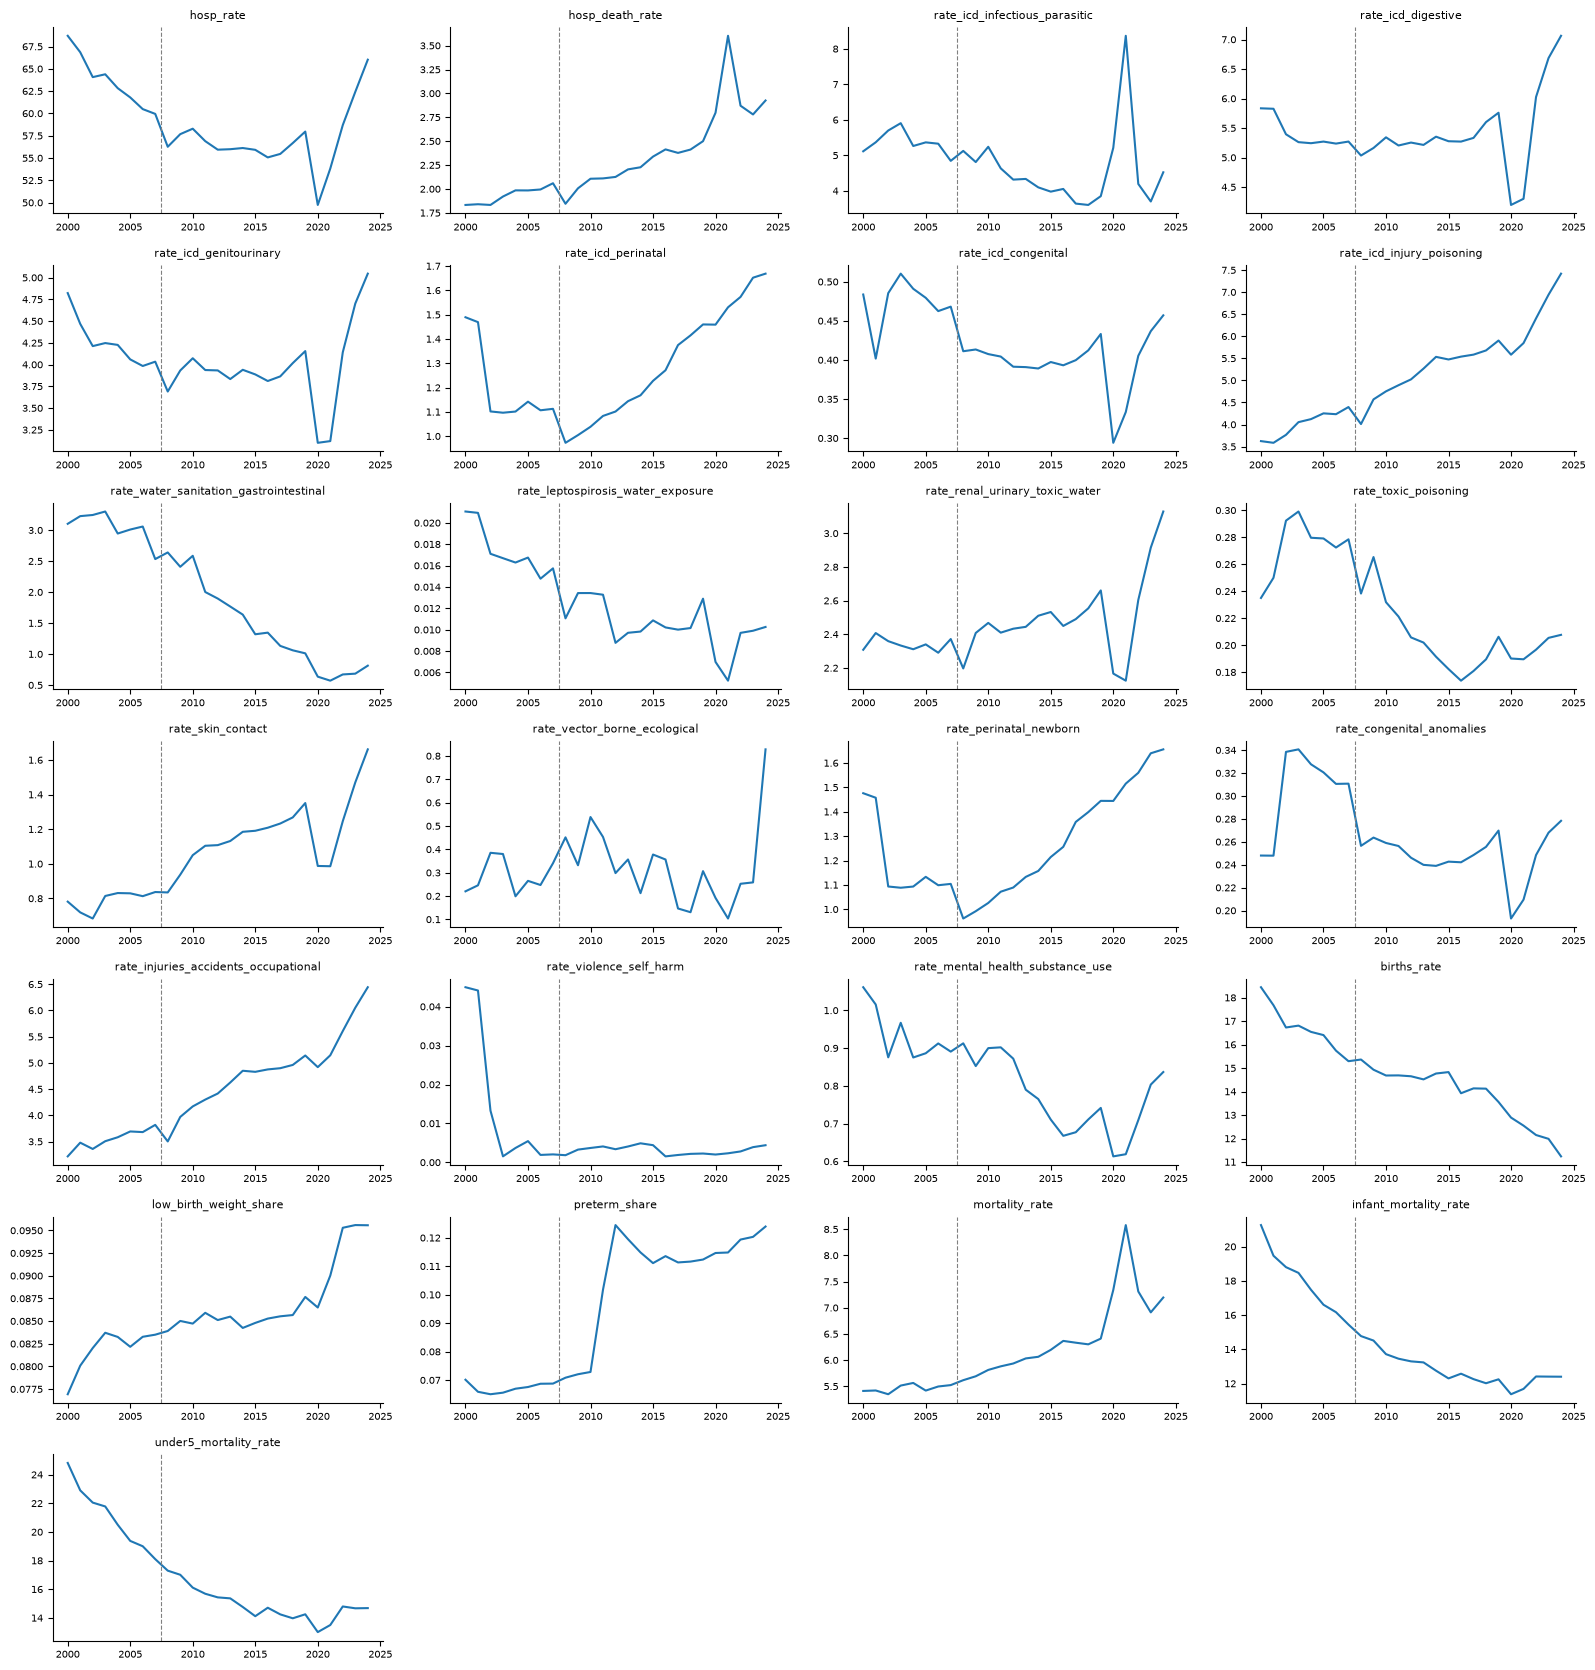

In [11]:
def population_weighted_mean(values, weights):
    observed = values.notna() & weights.notna()
    return np.average(values[observed], weights=weights[observed]) if observed.any() else np.nan

national = df.groupby("year").apply(
    lambda d: pd.Series({c: population_weighted_mean(d[c], d["population"]) for c in RATE_COLUMNS})
)
n_cols = 4
n_rows = int(np.ceil(len(RATE_COLUMNS) / n_cols))
fig, axes = plt.subplots(n_rows, n_cols, figsize=(4 * n_cols, 2.4 * n_rows))
for ax, column in zip(axes.flat, RATE_COLUMNS):
    national[column].plot(ax=ax)
    ax.axvline(2007.5, ls="--", color="grey", lw=0.8)
    ax.set_title(column, fontsize=8); ax.tick_params(labelsize=7); ax.set_xlabel("")
for ax in axes.flat[len(RATE_COLUMNS):]:
    ax.axis("off")
plt.tight_layout(); plt.show()

**Findings (run of 2026-10-22).**
- **Zeros and noise.** ICD-chapter rates have few zeros, except congenital (14%) and
  perinatal (6%). Infant and under-5 mortality are zero in 22% and 19% of
  municipality-years. Dispersion falls steadily with population, most steeply for the
  birth-based rates: the coefficient of variation is 1.9 in the smallest decile vs 0.39
  in the largest for infant mortality, and 0.79 vs 0.17 for the LBW share. That argues
  for population weights or PPML with population (or births) as exposure.
- **National series.** All-cause hospitalization falls from 69 to 55 per 1,000 between
  2000 and 2019, with a small step at the 2008 SIH switch, then dips in 2020–21 (COVID)
  and recovers to 66 by 2024. The infectious chapter, in-hospital deaths and all-cause
  mortality (5.4 → 8.6 per 1,000) peak in 2021, so 2020–21 need care (year FE, or
  exclusion as robustness).
- **Mortality.** Infant mortality falls from 21 to 12 per 1,000 live births between 2000
  and 2015 and is flat afterwards; under-5 mortality falls from 25 to 15.
- **Preterm break.** The preterm share jumps from 7% in 2010 to 10% in 2011 and 12.5%
  in 2012, in line with the 2011 SINASC form change in how gestational age is recorded.
  It is a measurement break, so preterm should be used only within 2012–2024 or with care.
  The LBW share rises smoothly from 7.7% to 8.7% (2000–2019), with a step to 9.5% in
  2021–22.

**→ Informs:** outcome set (water-related channels vs placebo channels), rates vs. counts
(OLS on log rates vs. PPML), population weights, zero handling for small channels, and
treatment of the 2007/2008 SIH break (year FE, source-system interaction, or post-2008
only).

## 3. Outcome variance decomposition

In [12]:
log_rates = np.log(df[RATE_COLUMNS].where(df[RATE_COLUMNS] > 0))
log_rates[["mun_id", "year", "state_year", "biome_year"]] = df[["mun_id", "year", "state_year", "biome_year"]]
OUTCOME_FE_SETS = {
    "mun": ["mun_id"],
    "mun + year": ["mun_id", "year"],
    "mun + biome×year": ["mun_id", "biome_year"],
    "mun + state×year": ["mun_id", "state_year"],
}
display(desc.variation_table(log_rates, RATE_COLUMNS, OUTCOME_FE_SETS).filter(like="share:"))

,share: mun,share: mun + year,share: mun + biome×year,share: mun + state×year
hosp_rate,0.4124,0.3827,0.3724,0.3406
hosp_death_rate,0.4351,0.2721,0.2652,0.2462
rate_icd_infectious_parasitic,0.49,0.4404,0.4173,0.3838
rate_icd_digestive,0.5059,0.4466,0.4419,0.4137
rate_icd_genitourinary,0.5238,0.4923,0.4816,0.4497
rate_icd_perinatal,0.6568,0.5677,0.5575,0.5145
rate_icd_congenital,0.6587,0.6369,0.6293,0.6033
rate_icd_injury_poisoning,0.6086,0.3818,0.3763,0.33
rate_water_sanitation_gastrointestinal,0.518,0.318,0.308,0.2888
rate_leptospirosis_water_exposure,0.1601,0.1461,0.1434,0.1334


**Findings (run of 2026-10-22).** Municipality FE leave 40–65% of the variance in log ICD-chapter rates, and adding
state×year FE removes another 5–15 pp. In-hospital deaths, all-cause mortality and the
injury chapter respond most to year effects (secular trends). LBW (76%), infant (62%) and
under-5 mortality (64%) keep most of their variance after all FE. Most of it is
small-municipality noise (see the dispersion table).

**→ Informs:** FE structure (year vs. biome×year vs. state×year) and how much outcome variation is left to explain.

## 4. Land-cover exposure: levels and identifying variation

In [13]:
LC = panels.LAND_COVER_SHARE_COLUMNS
ALR = panels.LAND_COVER_ALR_COLUMNS
display(df[LC + ALR].describe(percentiles=[0.01, 0.1, 0.5, 0.9, 0.99]).T)
EXPOSURE_FE_SETS = {
    "mun": ["mun_id"],
    "mun + year": ["mun_id", "year"],
    "mun + state×year": ["mun_id", "state_year"],
}
display(desc.variation_table(df, LC + ALR, EXPOSURE_FE_SETS))

,count,mean,std,min,1%,10%,50%,90%,99%,max
lc_forest,1.337e+05,0.4137,0.252,0,0.04694,0.1229,0.367,0.8017,0.9757,1
lc_nonforest_nat,1.337e+05,0.04032,0.09501,0,0,1.882e-05,0.009151,0.1015,0.5402,0.9566
lc_pasture,1.337e+05,0.2715,0.2079,0,0,0.02436,0.2367,0.5699,0.7876,1
lc_agriculture,1.337e+05,0.1214,0.1796,0,0,6.562e-05,0.02964,0.3927,0.7506,0.913
lc_farming_unclassified,1.337e+05,0.1289,0.1047,0,0,0.008214,0.1112,0.2675,0.4158,0.8789
lc_urban,1.337e+05,0.01357,0.0374,0,0,0.0003129,0.004869,0.02815,0.1559,0.9996
lc_mining,1.337e+05,0.0005363,0.004041,0,0,0,0,0.0006107,0.01155,0.2194
lc_other,1.337e+05,0.001239,0.003068,0,0,2.148e-05,0.0006339,0.002685,0.009037,0.1295
lc_water,1.337e+05,0.008869,0.01912,0,0,0.0002268,0.002762,0.02296,0.09293,0.3984
alr_pasture,1.337e+05,-0.9097,1.94,-9.21,-8.753,-3.076,-0.5619,1.049,2.167,9.21


,n,sd_total,sd: mun,share: mun,sd: mun + year,share: mun + year,sd: mun + state×year,share: mun + state×year
lc_forest,1.337e+05,0.252,0.02336,0.008589,0.02164,0.007376,0.01646,0.004266
lc_nonforest_nat,1.337e+05,0.09501,0.01125,0.01403,0.01093,0.01323,0.00876,0.008502
lc_pasture,1.337e+05,0.2079,0.04201,0.04083,0.03978,0.03662,0.02937,0.01995
lc_agriculture,1.337e+05,0.1796,0.02925,0.02651,0.02537,0.01995,0.02179,0.01472
lc_farming_unclassified,1.337e+05,0.1047,0.0238,0.05166,0.02187,0.04362,0.01977,0.03565
lc_urban,1.337e+05,0.0374,0.003912,0.01094,0.003453,0.008527,0.003264,0.007618
lc_mining,1.337e+05,0.004041,0.001038,0.06596,0.001026,0.0645,0.001005,0.06191
lc_other,1.337e+05,0.003068,0.0007934,0.0669,0.0007901,0.06634,0.0007727,0.06345
lc_water,1.337e+05,0.01912,0.002519,0.01736,0.002487,0.01691,0.002355,0.01517
alr_pasture,1.337e+05,1.94,0.2641,0.01852,0.2613,0.01814,0.1997,0.01059


In [14]:
first_obs = df[df["year"] == ANALYSIS_YEARS[0]].set_index("mun_id")[LC]
last_obs = df[df["year"] == ANALYSIS_YEARS[1]].set_index("mun_id")[LC]
long_diff = (last_obs - first_obs).dropna()
summary = long_diff.describe(percentiles=[0.05, 0.25, 0.5, 0.75, 0.95]).T
for threshold in (0.01, 0.05):
    summary[f"share |Δ| > {threshold:.0%}"] = (long_diff.abs() > threshold).mean()
print(f"Long difference {ANALYSIS_YEARS[0]}→{ANALYSIS_YEARS[1]}, {len(long_diff):,} municipalities")
display(summary)
display(long_diff.groupby(df.drop_duplicates("mun_id").set_index("mun_id")["biome"]).mean())

Long difference 2000→2024, 5,347 municipalities


,count,mean,std,min,5%,25%,50%,75%,95%,max,share |Δ| > 1%,share |Δ| > 5%
lc_forest,"5,347",-0.03465,0.06982,-0.5625,-0.1782,-0.05944,-0.01162,0.008518,0.03339,0.1869,0.7458,0.3076
lc_nonforest_nat,"5,347",-0.008909,0.0346,-0.4334,-0.05048,-0.003226,-0.0001534,8.887e-05,0.002606,0.1506,0.1444,0.05199
lc_pasture,"5,347",-0.04375,0.1213,-0.6462,-0.2779,-0.09359,-0.02416,0.02173,0.1302,0.5588,0.8683,0.545
lc_agriculture,"5,347",0.04117,0.07112,-0.7,-0.01787,0.0005287,0.01361,0.0645,0.1798,0.835,0.6056,0.3144
lc_farming_unclassified,"5,347",0.03878,0.06031,-0.3752,-0.0358,0.00182,0.02852,0.06658,0.1415,0.5,0.8122,0.3737
lc_urban,"5,347",0.005943,0.01101,-0.003805,0,0.0009721,0.002877,0.005999,0.02311,0.2,0.1427,0.01272
lc_mining,"5,347",0.0005413,0.003598,-2.888e-06,0,0,0,7.297e-05,0.001815,0.1425,0.01197,0.0009351
lc_other,"5,347",0.0002507,0.002471,-0.04621,-0.00138,-6.388e-05,0.0002146,0.0006738,0.001835,0.108,0.00505,0.000187
lc_water,"5,347",0.000617,0.00365,-0.1219,-0.001709,-0.0002206,0.0001477,0.0009401,0.005176,0.05608,0.01982,0.000374


,lc_forest,lc_nonforest_nat,lc_pasture,lc_agriculture,lc_farming_unclassified,lc_urban,lc_mining,lc_other,lc_water
biome,,,,,,,,,
Amazônia,-0.1206,-0.002275,0.08568,0.03096,0.004021,0.001719,0.001498,-0.0006886,-0.0003417
Caatinga,-0.04635,0.0005056,0.006655,0.01603,0.01667,0.005247,5.87e-05,0.000284,0.0009043
Cerrado,-0.0619,-0.004654,-0.05537,0.06724,0.04926,0.004216,0.0005576,-0.000304,0.000948
Mata Atlântica,-0.003999,-0.008625,-0.08698,0.04089,0.04889,0.00793,0.0005717,0.0006711,0.0006455
Pampa,0.004178,-0.1329,-0.004659,0.06835,0.06078,0.003573,0.0001364,-2.566e-05,0.0005765
Pantanal,-0.04524,0.01563,0.01545,0.02109,0.01941,0.001011,0.0006792,-0.0003003,-0.02773


In [15]:
alr_within = desc.demean(df, ALR, ["mun_id", "state_year"])
corr = alr_within.corr()
display(corr.round(2))
display(pd.Series(np.diag(np.linalg.inv(corr.to_numpy())), index=ALR, name="VIF (within)").to_frame().T)

,alr_pasture,alr_agriculture,alr_farming_unclassified,alr_urban,alr_mining,alr_other
alr_pasture,1,0.06,0.21,0.25,0.22,0.14
alr_agriculture,0.06,1,0.11,0.13,0.11,0.05
alr_farming_unclassified,0.21,0.11,1,0.17,0.13,0.08
alr_urban,0.25,0.13,0.17,1,0.25,0.18
alr_mining,0.22,0.11,0.13,0.25,1,0.08
alr_other,0.14,0.05,0.08,0.18,0.08,1


,alr_pasture,alr_agriculture,alr_farming_unclassified,alr_urban,alr_mining,alr_other
VIF (within),1.14,1.033,1.076,1.157,1.107,1.045


**Findings (run of 2026-10-22).**
- **Identifying variation.** As on the sensor side, very little exposure variation
  survives the FE: 0.4–2% of the share variance after municipality + state×year FE.
- **Long differences.** They are large, though: 55% of municipalities saw upstream
  pasture move by more than 5 pp between 2000 and 2024.
- **Biome patterns.** The Amazon shows forest-to-pasture conversion (−12 pp forest,
  +9 pp pasture on average). Cerrado and Mata Atlântica show pasture-to-agriculture
  conversion (pasture −6 to −9 pp, agriculture +4 to +7 pp). The same regressor
  therefore captures different transitions by biome.
- **Collinearity.** Within-FE ALR correlations are at most 0.25.

**→ Informs:** which classes are estimable, FE cost in identifying variation, and heterogeneity by biome.

## 5. Local vs. upstream exposure and distance weighting

The ADM2 exposure in `adm2_panel` is built from 25 km rings along the river network
(`src/data/shared/adm2_upstream_buckets.py`). Bucket 0 starts at the upstream end of each
municipality-touching trench; the rings of those trenches' own bodies are negative and
flagged `bucket_intersects_adm2`. Assembly builds two blocks from them:

- **upstream** (`lc_*`, `alr_*`, upstream climate): rings 0–500 km, weighted with the
  sensor side's **inv-sqrt kernel** (`DEFAULT_ADM2_DISTANCE_KERNEL`). It replaced a
  Gaussian with bandwidth 1,000,000 km, which weighted every ring equally; the switch
  leaves within-municipality land-cover changes ≥ 0.986 correlated with the flat version.
- **local** (`local_lc_*`, `local_alr_*`, `local_<climate>`): the flagged rings, equally
  weighted. Every matched municipality has them, so they are the panel's spine.
  **Headwater municipalities** (no upstream rings) stay in the panel with NaN upstream
  exposure and `has_upstream = False`.

Local is defined by the flag, not by the sign of the bucket: a few long upstream trenches
also get negative shifted distances without touching the municipality.

For health, separating *local* land use (which also acts through air quality, income,
occupation) from *upstream* land use (the water channel) is central to identification.

In [16]:
from src.data.shared.sensor_upstream import bucket_kernel_weights
from src.data.sources.land_cover.constants import LAND_COVER_COMPOSITION_BUCKET_MAP

midpoints = {b: m for b, (_label, m) in LAND_COVER_COMPOSITION_BUCKET_MAP.items()}
kernel_weights = pd.DataFrame({
    "gaussian, bw=1e6 (former default)": bucket_kernel_weights(list(midpoints.values()), kernel="gaussian",
                                                               bandwidth=1_000_000),
    "gaussian, bw=100": bucket_kernel_weights(list(midpoints.values()), kernel="gaussian", bandwidth=100),
    "inv_sqrt (sensor, assembly)": bucket_kernel_weights(list(midpoints.values()), kernel="inv_sqrt_distance"),
}, index=list(midpoints))
display((kernel_weights / kernel_weights.max()).T.round(3))

,0,25,50,75,100,125,150,175,200,225,250,275,300,325,350,375,400,425,450,475,500
"gaussian, bw=1e6 (former default)",1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1,1
"gaussian, bw=100",1,0.882,0.687,0.472,0.287,0.153,0.072,0.03,0.011,0.004,0.001,0,0,0,0,0,0,0,0,0,0
"inv_sqrt (sensor, assembly)",1,0.577,0.447,0.378,0.333,0.302,0.277,0.258,0.243,0.229,0.218,0.209,0.2,0.192,0.186,0.18,0.174,0.169,0.164,0.16,0.129


In [17]:
LC_ADM2_BUCKETED_PATH = PROJECT_ROOT / "data/land_cover/processed/aggregate/land_cover_adm2_upstream.parquet"
SNAPSHOT_YEARS = list(ANALYSIS_YEARS)
areas = pd.read_parquet(
    LC_ADM2_BUCKETED_PATH,
    columns=["mun_id", "year", "bucket", "n", "bucket_intersects_adm2"],
    filters=[("year", "==", SNAPSHOT_YEARS[0])],
).drop_duplicates(["mun_id", "bucket"])
areas["segment"] = np.where(areas["bucket_intersects_adm2"], "local",
                            np.where(areas["bucket"] >= 0, "upstream", "upstream (negative, unflagged)"))
display(areas.groupby("segment").agg(rings=("n", "size"), municipalities=("mun_id", "nunique"),
                                     area_share=("n", "sum")).assign(area_share=lambda t: t.area_share / t.area_share.sum()))

municipalities = df.drop_duplicates("mun_id")
print(f"Municipalities in panel: {len(municipalities):,}; headwater (no upstream rings): "
      f"{(~municipalities['has_upstream']).sum():,}; their share of hospitalizations: "
      f"{df.loc[~df['has_upstream'], 'hosp_hospitalizations_count'].sum() / df['hosp_hospitalizations_count'].sum():.1%}")
display(municipalities.loc[~municipalities["has_upstream"]].nlargest(8, "population")[["mun_id", "population", "biome"]])

,rings,municipalities,area_share
segment,,,
local,7122,5564,0.03424
upstream,44590,5347,0.9657
"upstream (negative, unflagged)",180,166,1.289e-05


Municipalities in panel: 5,564; headwater (no upstream rings): 217; their share of hospitalizations: 3.8%


,mun_id,population,biome
81100,330490,9.117e+05,Mata Atlântica
15875,211130,8.808e+05,Amazônia
61150,311860,5.485e+05,Mata Atlântica
80475,330330,4.701e+05,Mata Atlântica
109825,420540,3.504e+05,Mata Atlântica
86850,351870,2.697e+05,Mata Atlântica
96250,355280,2.013e+05,Mata Atlântica
93025,354100,1.971e+05,Mata Atlântica


Do local and upstream land-cover change move together? If highly correlated, the two channels cannot be separated.

In [18]:
EXPOSURE_CLASSES = ["forest", "pasture", "agriculture", "urban", "mining"]
with_upstream = df[df["has_upstream"]]
first = with_upstream[with_upstream["year"] == SNAPSHOT_YEARS[0]].set_index("mun_id")
last = with_upstream[with_upstream["year"] == SNAPSHOT_YEARS[1]].set_index("mun_id")
rows = {}
for land_cover_class in EXPOSURE_CLASSES:
    local, upstream = f"local_lc_{land_cover_class}", f"lc_{land_cover_class}"
    change = (last[[local, upstream]] - first[[local, upstream]]).dropna()
    rows[land_cover_class] = {
        "n_municipalities": len(change),
        "corr(level local, level upstream)": first[local].corr(first[upstream]),
        "corr(Δlocal, Δupstream)": change[local].corr(change[upstream]),
        "sd Δlocal": change[local].std(),
        "sd Δupstream": change[upstream].std(),
    }
display(pd.DataFrame(rows).T)

local_alr = [f"local_{column}" for column in panels.LAND_COVER_ALR_COLUMNS]
within = desc.demean(with_upstream, local_alr + panels.LAND_COVER_ALR_COLUMNS, ["mun_id", "state_year"])
display(pd.Series({column: within[f"local_{column}"].corr(within[column]) for column in panels.LAND_COVER_ALR_COLUMNS},
                  name="within corr(local, upstream), mun + state×year FE").round(2).to_frame().T)

,n_municipalities,"corr(level local, level upstream)","corr(Δlocal, Δupstream)",sd Δlocal,sd Δupstream
forest,"5,347",0.8908,0.7889,0.07392,0.06982
pasture,"5,347",0.8444,0.86,0.1328,0.1213
agriculture,"5,347",0.8451,0.7751,0.08187,0.07112
urban,"5,347",0.5586,0.5471,0.01314,0.01101
mining,"5,347",0.3031,0.339,0.002962,0.003598


,alr_pasture,alr_agriculture,alr_farming_unclassified,alr_urban,alr_mining,alr_other
"within corr(local, upstream), mun + state×year FE",0.52,0.46,0.52,0.2,0.28,0.31


**Upstream reach.** The pollution arm caps upstream land cover at 200 km
(`pollution.MAX_UPSTREAM_KM`) and checks distance bands as robustness. How far do
municipalities' upstream rings extend, how much does the cap change the exposure, and
can near and far rings be separated?

In [19]:
from src.analysis import pollution

REACH_KM = pollution.MAX_UPSTREAM_KM
furthest_ring = (pd.read_parquet(panels.LAND_COVER_ADM2_BUCKETED_PATH, columns=["mun_id", "bucket"],
                                 filters=[("year", "==", ANALYSIS_YEARS[0]), ("bucket", ">=", 0)])
                 .groupby("mun_id")["bucket"].max())
display(pd.Series({
    "municipalities with upstream rings": len(furthest_ring),
    "median furthest ring (km)": furthest_ring.median(),
    "share: first ring only": (furthest_ring == 0).mean(),
    f"share: nothing beyond {REACH_KM} km": (furthest_ring < REACH_KM).mean(),
    "share: reach the 500 km+ ring": (furthest_ring == 500).mean(),
}).to_frame("furthest upstream ring").T)

reach_variants = {"full": (0, np.inf), "capped": (0, REACH_KM),
                  **{f"band {band}": limits for band, limits in pollution.DISTANCE_BANDS.items()}}
reach = df[["mun_id", "year", "state_year"]]
for label, (lower, upper) in reach_variants.items():
    variant = panels.adm2_upstream_land_cover(lower, upper, years=ANALYSIS_YEARS)[["mun_id", "year", *ALR]]
    reach = reach.merge(variant.rename(columns={c: f"{c} | {label}" for c in ALR}), on=["mun_id", "year"], how="left")

def within_corr(column, a, b):
    pair = [f"{column} | {a}", f"{column} | {b}"]
    return desc.demean(reach, pair, ["mun_id", "state_year"]).corr().iloc[0, 1]

display(pd.DataFrame({
    column: {
        f"capped ({REACH_KM} km) vs full": within_corr(column, "capped", "full"),
        "0–50 vs 50–150 km": within_corr(column, "band 0_50", "band 50_150"),
        "0–50 vs 150–500 km": within_corr(column, "band 0_50", "band 150_500"),
    }
    for column in ALR
}).T.round(2).rename_axis("within corr (mun + state×year FE)", axis=1))

,municipalities with upstream rings,median furthest ring (km),share: first ring only,share: nothing beyond 200 km,share: reach the 500 km+ ring
furthest upstream ring,"5,347",100,0.1833,0.6308,0.179


FloatProgress(value=0.0, layout=Layout(width='auto'), style=ProgressStyle(bar_color='black'))

FloatProgress(value=0.0, layout=Layout(width='auto'), style=ProgressStyle(bar_color='black'))

within corr (mun + state×year FE),capped (200 km) vs full,0–50 vs 50–150 km,0–50 vs 150–500 km
alr_pasture,0.99,0.53,0.29
alr_agriculture,0.96,0.5,0.14
alr_farming_unclassified,0.97,0.48,0.2
alr_urban,0.99,0.23,0.02
alr_mining,0.96,0.2,0.13
alr_other,0.98,0.32,0.1


**Findings (run of 2026-10-22).**
- **What the exposure covers.** Local (municipality-touching) rings are 3% of total
  ring area; the upstream block covers the rest. 217 headwater municipalities (3.8% of
  hospitalizations, e.g. São Gonçalo, São Luís, Niterói, Florianópolis) have local rings
  only and enter with `has_upstream = False`.
- **Reach.** The median municipality's upstream rings end at 100 km; 18% have only the
  first ring and 63% nothing beyond 200 km, while 18% reach the 500 km+ ring. Capping at
  200 km changes little within municipality (capped vs full ALR correlate 0.96–0.99), and
  near and far rings move separately (0–50 vs 150–500 km: 0.02–0.29), so distance bands
  are estimable as a robustness check.
- **Local vs upstream.** Changes from 2000 to 2024 are highly correlated (forest 0.79,
  pasture 0.86, agriculture 0.78, urban 0.55, mining 0.34). After municipality +
  state×year FE the ALR terms still correlate at 0.20–0.52. The two blocks can be
  separated, but upstream coefficients without the local block would also pick up local
  land-use change, which acts on health through non-water channels (income, fires,
  occupation).

**→ Informs:** the exposure definition (local and upstream blocks; headwater
municipalities enter with `has_upstream = False`, their upstream exposure set to zero and
absorbed by the municipality FE), and the upstream reach (inv-sqrt kernel capped at
200 km as in the pollution arm, distance bands as robustness).

## 6. Controls

In [20]:
CLIMATE = panels.CLIMATE_VARIABLES
LOCAL_CLIMATE = [f"local_{variable}" for variable in CLIMATE]
display(df[CLIMATE + LOCAL_CLIMATE + ["population"]].describe().T)
climate_within = desc.demean(df[df["has_upstream"]].dropna(subset=CLIMATE + LOCAL_CLIMATE),
                             CLIMATE + LOCAL_CLIMATE, ["mun_id", "state_year"])
display(climate_within[CLIMATE].corr().round(2))
display(pd.Series({variable: climate_within[f"local_{variable}"].corr(climate_within[variable]) for variable in CLIMATE},
                  name="within corr(local, upstream)").round(2).to_frame().T)

,count,mean,std,min,25%,50%,75%,max
2t,1.337e+05,22.57,3.162,13.33,19.89,22.9,25.23,29.46
2d,1.337e+05,16.74,2.45,10.42,14.93,16.25,18.29,24.18
tp,1.337e+05,3.616,1.501,0.212,2.478,3.663,4.593,10.65
sro,1.337e+05,0.2956,0.2654,0.0006087,0.1156,0.255,0.3907,3.39
ssro,1.337e+05,0.7386,0.758,0,0.05292,0.5173,1.219,5.738
pev,1.337e+05,-8.667,3.076,-32.92,-9.561,-7.996,-6.715,-3.821
swvl1,1.337e+05,0.3258,0.08986,0.06294,0.2593,0.342,0.4009,0.4843
swvl2,1.337e+05,0.3391,0.0814,0.06107,0.2797,0.3503,0.4056,0.4974
2t_daily_min,1.337e+05,10.58,7.055,-5.276,5.275,10.82,16.88,23.65
2t_daily_max,1.337e+05,34.63,2.446,24.4,32.9,34.83,36.48,42.42


,2t,2d,tp,sro,ssro,pev,swvl1,swvl2,2t_daily_min,2t_daily_max
2t,1,-0.66,-0.43,-0.19,-0.13,-0.57,-0.67,-0.63,0.13,0.37
2d,-0.66,1,0.38,0.14,0.02,0.52,0.65,0.6,0.03,-0.35
tp,-0.43,0.38,1,0.76,0.72,0.39,0.52,0.53,0.02,-0.22
sro,-0.19,0.14,0.76,1,0.53,0.19,0.23,0.26,0.02,-0.11
ssro,-0.13,0.02,0.72,0.53,1,0.15,0.08,0.09,0.02,-0.1
pev,-0.57,0.52,0.39,0.19,0.15,1,0.52,0.5,-0.04,-0.24
swvl1,-0.67,0.65,0.52,0.23,0.08,0.52,1,0.95,-0.04,-0.3
swvl2,-0.63,0.6,0.53,0.26,0.09,0.5,0.95,1,-0.03,-0.29
2t_daily_min,0.13,0.03,0.02,0.02,0.02,-0.04,-0.04,-0.03,1,0.01
2t_daily_max,0.37,-0.35,-0.22,-0.11,-0.1,-0.24,-0.3,-0.29,0.01,1


,2t,2d,tp,sro,ssro,pev,swvl1,swvl2,2t_daily_min,2t_daily_max
"within corr(local, upstream)",0.93,0.94,0.9,0.8,0.87,0.78,0.89,0.88,0.87,0.88


**Findings (run of 2026-10-22).** Upstream annual precipitation, runoff and sub-surface runoff are strongly correlated
within municipality (0.72–0.76), and so are the two soil-moisture layers (0.95). A
parsimonious set (temperature, precipitation, one soil-moisture layer) loses little.
Local and upstream climate are close substitutes within municipality (0.79–0.94; 0.93
for temperature, 0.90 for precipitation), so local climate alone is a natural control
set. Two coastal municipalities have no local ERA5-Land cells.

The upstream climate block uses the same rings and kernel as upstream land cover; the
local block (`local_<climate>`) averages the municipality's own catchment rings, a direct
confounder for health (heat, rainfall at the municipality).

**→ Informs:** climate control set (local, upstream or both), and whether population
enters as control, weight or exposure.

## 7. Inference structure

In [21]:
municipalities = df.drop_duplicates("mun_id")
cluster_levels = {"state": "state", **{f"Otto {level}": f"otto_basin_l{level}" for level in (2, 3, 4, 5)}}
display(pd.DataFrame({
    label: {
        "clusters": municipalities[column].nunique(),
        "effective (inverse HHI)": desc.effective_cluster_count(municipalities.groupby(column).size()),
        "largest share": municipalities[column].value_counts(normalize=True).iloc[0],
    }
    for label, column in cluster_levels.items()
}).T.round(3))
display(df.groupby("biome_year")["mun_id"].nunique().describe().rename("municipalities per biome×year").to_frame().T)

,clusters,effective (inverse HHI),largest share
state,27,13.99,0.153
Otto 2,39,7.116,0.251
Otto 3,217,38.89,0.065
Otto 4,821,193.8,0.018
Otto 5,"2,194",829.6,0.008


,count,mean,std,min,25%,50%,75%,max
municipalities per biome×year,150,927.3,897.1,9,160,799,"1,102","2,695"


**Findings (run of 2026-10-22).** There are 27 states, effective about 14, so state clustering is a few-cluster problem.
Otto-3 basins (dominant per municipality by drainage area) give 217 clusters, effective
about 39, with the largest holding 6.5% of municipalities; Otto 2 is too coarse
(effective about 7). Otto 3 matches the sensor-side choice.

Upstream exposure is shared by municipalities on the same river, so errors are
correlated along river systems, not just within states. `adm2_panel` carries each
municipality's dominant Otto basin at levels 2–5 (largest summed drainage area of its
intersecting trenches), so clustering can follow the sensor side (Otto 3).

**→ Informs:** cluster level (municipality, state, Otto basin, or spatial HAC).

## 8. Raw within-municipality associations

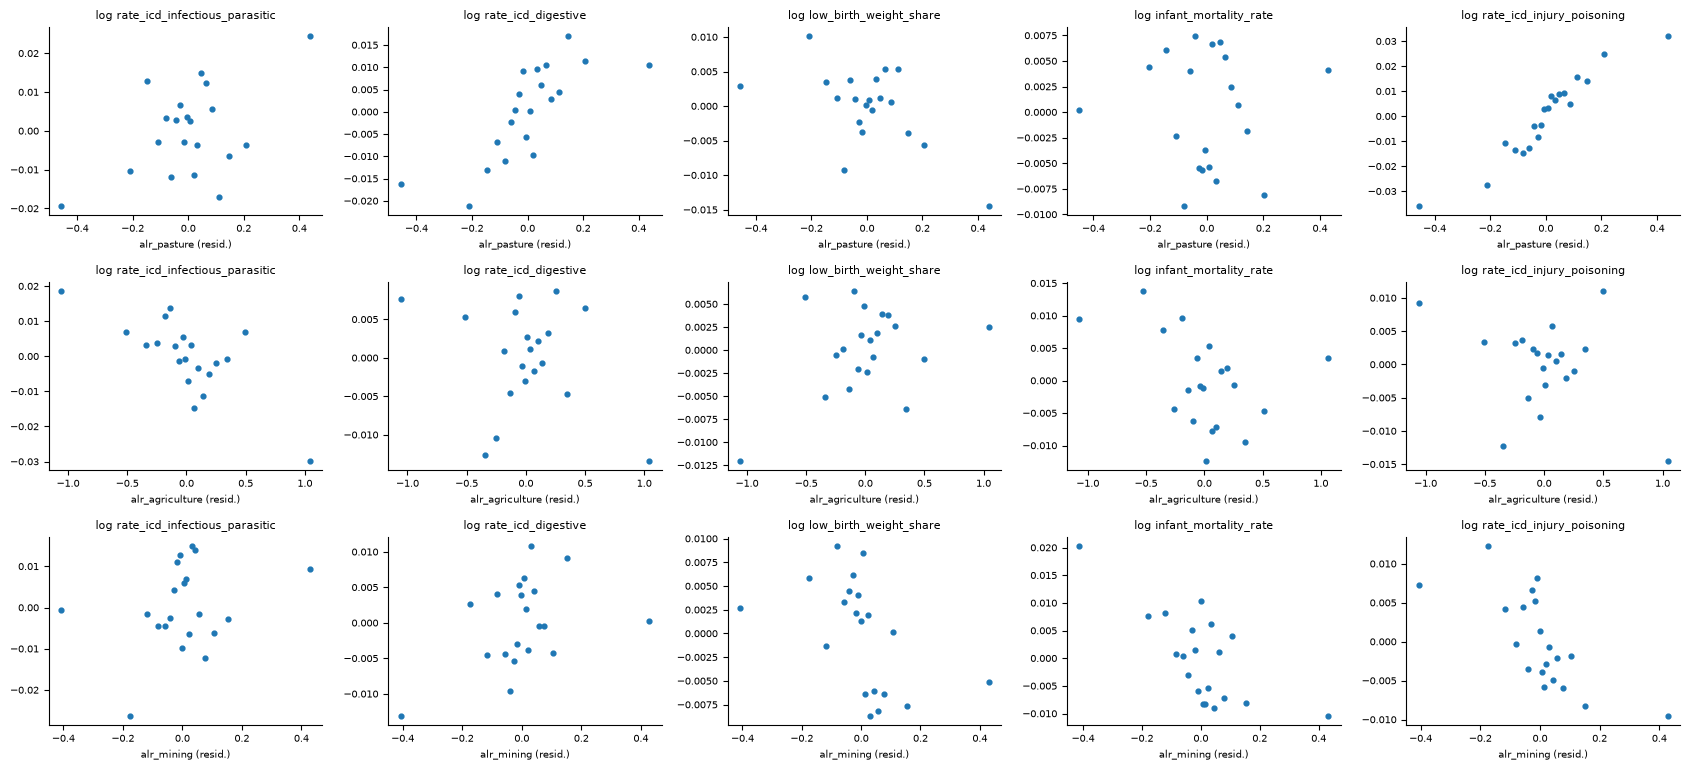

In [22]:
KEY_OUTCOMES = ["rate_icd_infectious_parasitic", "rate_icd_digestive", "low_birth_weight_share",
                "infant_mortality_rate", "rate_icd_injury_poisoning"]
KEY_REGRESSORS = ["alr_pasture", "alr_agriculture", "alr_mining"]
frame = log_rates[["mun_id", "state_year"]].join(log_rates[KEY_OUTCOMES]).join(df[KEY_REGRESSORS])
fig, axes = plt.subplots(len(KEY_REGRESSORS), len(KEY_OUTCOMES),
                         figsize=(3.4 * len(KEY_OUTCOMES), 2.6 * len(KEY_REGRESSORS)), squeeze=False)
for i, regressor in enumerate(KEY_REGRESSORS):
    for j, outcome in enumerate(KEY_OUTCOMES):
        residuals = desc.demean(frame, [outcome, regressor], ["mun_id", "state_year"])
        bins = desc.binscatter(residuals[regressor], residuals[outcome])
        axes[i, j].scatter(bins["x"], bins["y"], s=12)
        axes[i, j].set_title(f"log {outcome}", fontsize=8)
        axes[i, j].set_xlabel(f"{regressor} (resid.)", fontsize=7)
        axes[i, j].tick_params(labelsize=7)
plt.tight_layout(); plt.show()

**Findings (run of 2026-10-22).** In the raw binscatters (unweighted log rates, zeros dropped, no controls), injury/poisoning
hospitalizations rise steeply and monotonically with upstream pasture after FE, as do
digestive hospitalizations, so the placebo would fail. Infectious/parasitic, LBW and
infant mortality show no clear pattern; log infant mortality drops the 22% of
municipality-years without an infant death. The check below tests whether the placebo
pattern survives the candidate specification.

**Placebo under the candidate specification.** The binscatter uses unweighted log rates
(zeros dropped) and no controls. Below, the specification decided in §9: PPML on counts
with log population as exposure (log births for infant deaths and low birth weight),
municipality + state×year FE, local climate (temperature, precipitation, top-layer soil
moisture), upstream ALR capped at 200 km (headwater municipalities set to 0, absorbed by
the FE) and Otto-3 clustered SEs. Three exposure sets: upstream only, plus the local
block, plus the all-cause hospitalization rate as a utilization control. This is a
diagnostic for the design choices, not a result.

In [23]:
import warnings

import pyfixest as pf

CLASSES = [column.removeprefix("alr_") for column in pollution.LAND_COVER_REGRESSORS]
capped = panels.adm2_upstream_land_cover(max_km=REACH_KM, years=ANALYSIS_YEARS)
model_frame = df.merge(capped[["mun_id", "year", *pollution.LAND_COVER_REGRESSORS]]
                       .rename(columns={f"alr_{c}": f"up_{c}" for c in CLASSES}),
                       on=["mun_id", "year"], how="left", validate="one_to_one")
for c in CLASSES:
    model_frame[f"up_{c}"] = model_frame[f"up_{c}"].fillna(0.0)
    model_frame[f"loc_{c}"] = model_frame[f"local_alr_{c}"]
model_frame["log_population"] = np.log(model_frame["population"])
model_frame["log_births"] = np.log(model_frame["births"].where(model_frame["births"] > 0))
model_frame["log_births_weight_known"] = np.log(model_frame["births_weight_known"].where(model_frame["births_weight_known"] > 0))
model_frame["log_hosp_rate"] = np.log(model_frame["hosp_rate"].where(model_frame["hosp_rate"] > 0))

PLACEBO_OUTCOMES = {  # label: (count, exposure)
    "injury/poisoning (ICD 19, placebo)": ("hosp_icd_injury_poisoning", "log_population"),
    "injuries channel (placebo)": ("hosp_injuries_accidents_occupational", "log_population"),
    "digestive (ICD 11)": ("hosp_icd_digestive", "log_population"),
    "infectious/parasitic (ICD 01)": ("hosp_icd_infectious_parasitic", "log_population"),
    "gastrointestinal channel": ("hosp_water_sanitation_gastrointestinal", "log_population"),
    "infant deaths": ("deaths_under_1", "log_births"),
    "low birth weight": ("births_low_weight", "log_births_weight_known"),
}
UPSTREAM = " + ".join(f"up_{c}" for c in CLASSES)
LOCAL = " + ".join(f"loc_{c}" for c in CLASSES)
EXPOSURE_SETS = {
    "upstream": UPSTREAM,
    "+ local": f"{UPSTREAM} + {LOCAL}",
    "+ local + hosp rate": f"{UPSTREAM} + {LOCAL} + log_hosp_rate",
}
SHOWN_TERMS = ["up_pasture", "up_agriculture", "loc_pasture", "loc_agriculture"]
placebo_rows = []
for label, (outcome, exposure) in PLACEBO_OUTCOMES.items():
    for exposure_set, rhs in EXPOSURE_SETS.items():
        data = model_frame.dropna(subset=[outcome, exposure, "local_2t", "loc_pasture", "log_hosp_rate", "otto_basin_l3"])
        with warnings.catch_warnings():  # singleton FE and separated observations are dropped (< 0.1% of rows)
            warnings.simplefilter("ignore", UserWarning)
            fit = pf.fepois(f"{outcome} ~ {rhs} + local_2t + local_tp + local_swvl1 | mun_id + state_year", data=data,
                            offset=exposure, vcov={"CRV1": "otto_basin_l3"})
        tidy = fit.tidy()
        placebo_rows += [{"outcome": label, "exposure set": exposure_set, "term": term,
                          "cell": f"{tidy.loc[term, 'Estimate']:+.3f} ({tidy.loc[term, 'Std. Error']:.3f})"}
                         for term in SHOWN_TERMS if term in tidy.index]
placebo = (pd.DataFrame(placebo_rows)
           .pivot_table(index=["outcome", "exposure set"], columns="term", values="cell", aggfunc="first", sort=False)
           .reindex(columns=SHOWN_TERMS).fillna(""))
print(f"N = {fit._N:,} municipality-years (last model); estimate (Otto-3 clustered SE) on ALR terms")
display(placebo)

FloatProgress(value=0.0, layout=Layout(width='auto'), style=ProgressStyle(bar_color='black'))

N = 138,801 municipality-years (last model); estimate (Otto-3 clustered SE) on ALR terms


term                                                        up_pasture  up_agriculture     loc_pasture loc_agriculture
outcome                            exposure set                                                                       
injury/poisoning (ICD 19, placebo) upstream             +0.040 (0.032)  +0.025 (0.016)                                
                                   + local              +0.024 (0.029)  +0.015 (0.018)  +0.031 (0.028)  +0.010 (0.011)
                                   + local + hosp rate  +0.031 (0.024)  +0.021 (0.018)  +0.014 (0.022)  +0.009 (0.012)
injuries channel (placebo)         upstream             +0.036 (0.034)  +0.033 (0.017)                                
                                   + local              +0.019 (0.030)  +0.020 (0.020)  +0.033 (0.029)  +0.012 (0.012)
                                   + local + hosp rate  +0.025 (0.025)  +0.025 (0.020)  +0.018 (0.023)  +0.012 (0.013)
digestive (ICD 11)                 upstream             +0.004 (0.019)  +0.006 (0.010)                                
                                   + local              -0.006 (0.017)  +0.003 (0.011)  +0.015 (0.031)  -0.002 (0.007)
                                   + local + hosp rate  +0.002 (0.012)  +0.011 (0.005)  -0.003 (0.018)  -0.002 (0.005)
infectious/parasitic (ICD 01)      upstream             -0.002 (0.025)  -0.037 (0.017)                                
                                   + local              -0.037 (0.024)  -0.031 (0.018)  +0.071 (0.035)  -0.000 (0.016)
                                   + local + hosp rate  -0.026 (0.020)  -0.014 (0.007)  +0.045 (0.033)  -0.001 (0.008)
gastrointestinal channel           upstream             +0.003 (0.052)  -0.014 (0.016)                                
                                   + local              -0.084 (0.054)  -0.030 (0.022)  +0.160 (0.062)  +0.027 (0.020)
                                   + local + hosp rate  -0.094 (0.042)  -0.002 (0.013)  +0.160 (0.037)  +0.021 (0.012)
infant deaths                      upstream             -0.002 (0.017)  -0.019 (0.008)                                
                                   + local              -0.012 (0.018)  -0.013 (0.008)  +0.020 (0.016)  -0.008 (0.006)
                                   + local + hosp rate  -0.012 (0.017)  -0.013 (0.008)  +0.020 (0.017)  -0.008 (0.006)
low birth weight                   upstream             -0.002 (0.008)  +0.014 (0.005)                                
                                   + local              -0.001 (0.007)  +0.006 (0.004)  -0.002 (0.009)  +0.011 (0.004)
                                   + local + hosp rate  -0.001 (0.007)  +0.006 (0.004)  -0.002 (0.009)  +0.011 (0.004)

**Findings (run of 2026-10-22).**
- **Placebo.** Under the candidate specification the injury placebo is not significant:
  upstream pasture is +0.040 (SE 0.032) with upstream exposure only and +0.024 (0.029)
  with the local block; the injuries channel behaves the same. The binscatter slope came
  from unweighted log rates without controls. The placebo estimates stay positive and as
  large as any water outcome's, so the placebo also bounds what the design can detect.
- **Local block.** Adding it shrinks the placebo coefficients by about 40% and moves the
  water outcomes: local pasture enters the gastrointestinal channel at +0.160 (0.062),
  while upstream pasture turns negative (−0.084, 0.054). Upstream estimates without the
  local block mix the two.
- **Utilization control.** The all-cause rate narrows some SEs (gastrointestinal, local
  pasture: 0.062 → 0.037) but barely moves the estimates. It contains the outcomes, so it
  belongs in a robustness check, not the main model.
- **No consistent upstream pattern yet.** Upstream agriculture is negative for
  infectious hospitalizations (−0.037, 0.017) and infant deaths (−0.019, 0.008) but
  positive for LBW (+0.014, 0.005) with upstream exposure only. With about 39 effective
  Otto-3 clusters, these clustered SEs are likely too small; `02_analysis` should report
  wild cluster bootstrap p-values.

**→ Informs:** sign/shape priors, the exposure set (local block in the main model) and
the role of the utilization control (robustness only).

## 9. Decision table

Status (2026-10-22): all rows **decided** and implemented in `src/analysis/health.py` /
`02_analysis.ipynb`. The §8 placebo check uses this specification.

| Parameter | Evidence | Proposal | Status |
|---|---|---|---|
| Estimation window | §1: population from 2000, land cover to 2024; every outcome ≥ 98.7% covered in 2000, ≥ 99.6% from 2001. §2: SINASC changed how gestational age is recorded in 2011; COVID dip in hospitalizations and peak in mortality in 2020–21 | 2000–2024; preterm only 2012–2024. Robustness: drop 2020–21 | decided |
| Municipality sample | §0: 7 SIH codes not in the panel (0.56% of hospitalizations). §5: 217 headwater municipalities (3.8% of hospitalizations). §1: population missing for 1.1% of municipalities in 2000; §6: 2 coastal municipalities without local climate | All panel municipalities. Headwater municipalities stay in with upstream ALR set to 0 (absorbed by the municipality FE), so they help identify the local block and the state×year effects. Drop the 7 unmatched codes and municipality-years without population or local climate. Robustness: `has_upstream` only | decided |
| Outcome set | §0: morbidity channels complete for 1998–2024 and continuous across 2007/08. §2: zero shares; leptospirosis 89% zeros, violence/self-harm 94% (a few hundred cases a year) | Primary (water pathway): ICD 01 infectious/parasitic, ICD 11 digestive, gastrointestinal channel, infant deaths, low birth weight. Secondary: ICD 14 genitourinary, 16 perinatal, 17 congenital; renal, skin, leptospirosis, toxic-poisoning and vector-borne channels; under-5 deaths; preterm (2012–2024). Placebo: ICD 19 injury/poisoning, injuries and mental-health channels. Violence/self-harm dropped | decided |
| Estimator | §2: infant mortality is zero in 22% of municipality-years and congenital in 14%; log rates drop these zeros | PPML on counts with a log exposure offset: population for hospitalizations and all-cause deaths, live births for infant and under-5 deaths, births with known weight (gestation) for LBW (preterm). Robustness: OLS on log rates of positive observations, population-weighted | decided |
| Weighting | §2: the coefficient of variation falls with population, by up to 5× from the smallest to the largest decile (infant mortality, LBW) | No extra weights: PPML with an exposure offset already weights by expected counts. Population enters as exposure, not as a control | decided |
| SIH 2007/2008 break | §0: 2010/2006 national ratios 0.87–1.35 for channels and chapters (vector-borne 2.3: the 2010 dengue epidemic). §2: small step in the all-cause rate at 2008 | Absorbed by the state×year FE (the switch is national, in one year). Robustness: 2008–2024 only | decided |
| Fixed effects | §3: state×year FE absorb more outcome variance than biome×year or year FE (e.g. infectious: 49% left after municipality FE, 44% with year, 42% with biome×year, 38% with state×year). §4: 0.4–2% of exposure variance is left | Municipality + state×year (state health policy and SUS financing vary by state and year). Robustness: municipality + biome×year (the pollution arm's choice) | decided |
| Land-cover regressors | §4: within-FE ALR correlations ≤ 0.25, VIF ≤ 1.16 | As in the pollution arm: ALR pasture, agriculture, farming (unclassified), urban, other (`pollution.LAND_COVER_REGRESSORS`), upstream and local. Mining out of the main model (separate arm, as in pollution) | decided |
| Exposure definition | §5: local and upstream changes correlate 0.78–0.86 (forest, pasture, agriculture), within-FE ALR 0.20–0.52. §8: adding the local block shrinks the injury placebo by about 40% and moves the gastrointestinal estimates | Upstream and local blocks jointly; the upstream coefficients are effects net of local land use. Robustness: upstream only | decided |
| Distance kernel / reach | §5: median furthest ring 100 km; 63% of municipalities have nothing beyond 200 km; capped vs full ALR correlate 0.96–0.99 within municipality; 0–50 vs 150–500 km rings 0.02–0.29 | Inv-sqrt kernel capped at 200 km (`panels.adm2_upstream_land_cover(max_km=200)`), as in the pollution arm. Robustness: bands 0–50 / 50–150 / 150–500 km | decided |
| Climate controls | §6: local and upstream climate correlate 0.78–0.94 within municipality; runoff variables 0.72–0.76, the two soil-moisture layers 0.95 | Local annual temperature, precipitation and top-layer soil moisture (`local_2t`, `local_tp`, `local_swvl1`). Robustness: add the upstream climate block | decided |
| Utilization control | §8: the all-cause hospitalization rate does not respond to upstream pasture (+0.003, SE 0.015) and moves the placebo little | Not in the main model (it contains the outcomes: bad-control risk). Robustness: add the log all-cause hospitalization rate for hospitalization outcomes | decided |
| Clustering | §7: 27 states (effective 14); Otto-3 basins 217 (effective 39, largest 6.5% of municipalities); Otto 2 effective 7 | Otto-3 basins, as in the pollution arm, with wild cluster bootstrap p-values for the main coefficients (`inference.wild_cluster_bootstrap`). Sensitivity: state, Otto 4 | decided |
| Heterogeneity | §4: Amazon forest-to-pasture (−12 pp forest, +9 pp pasture) vs Cerrado / Mata Atlântica pasture-to-agriculture conversion | Pooled main model; biome interactions for Amazônia, Cerrado, Mata Atlântica and Caatinga (Pampa, 160 municipalities, and Pantanal, 9, pooled) | decided |
| Placebo | §8: not significant under the candidate specification (upstream pasture +0.024, SE 0.029 with the local block), but as large as any water outcome's estimate | Report the injury/poisoning chapter and injuries channel next to every main table; read a water-outcome estimate as evidence only where it differs from the placebo's | decided |